# Big Data Analysis
## ML pipelines in Spark: from raw columns (and raw text) to predictions

Goal for today:
- Understand what a **pipeline** is and why it replaces last week's step-by-step cells
- Tell **transformers** from **estimators**, and see how fitting on the wrong rows causes **data leakage**
- Build, evaluate, save and reload a pipeline for last week's question: is this property haunted?
- Tune **hyperparameters** with **cross-validation** (`CrossValidator`), without leaking
- Record every model with **MLflow**
- Turn free text into features: **tokenisation**, **stop words**, **TF-IDF** and **Word2Vec**
- Build a **text classification** pipeline with 18 classes, and judge it with **macro F1**

How to use this notebook:
- Run it in Databricks (Free Edition), top to bottom
- Read each picture before the code below it
- Most code cells are ready to run; you write code only in the exercises (cells with `# TODO`)
- Exercises are labelled Core or Practice
- Section 10 links today's steps to your project; the optional challenge at the very end is not part of the class

Dataset
- `haunted_houses.parquet`, the same file as last week (it stays in the `week10` folder): the National Anomalous Property Register (NAPR) of HMSPIA, the (fictional) agency that investigates properties behaving in ways physics cannot explain
- 5,000 properties, 26 columns: numbers, yes/no flags, categories and four free-text columns (what the estate agent, the cat, the vicar and the owner said)
- **Part A** predicts `haunted` (yes/no) from the structured columns, as last week
- **Part B** predicts `phenomenon_type` (18 classes) from the free text only. This is the same kind of task as the Mental Health project: one text in, one of several classes out

___

## 1) The big idea: a pipeline is a recipe

Last week every preparation step lived in its own cell: index the categories, one-hot encode them, assemble the numbers, scale them, assemble everything, train. It worked, but:
- the steps had to be run **in the right order**, by hand
- to score a new batch of properties next month, someone would have to repeat every cell exactly, with the settings learned from the old data
- some steps (the indexer, the scaler) learned from **all** rows, test rows included. Last week's notebook warned about this in section 6

A **pipeline** writes the steps down once, as a recipe: an ordered list of stages. You hand the recipe the training rows once (`.fit()`), and you get back a fitted pipeline, the `PipelineModel`, that applies every step, in order, to any new rows (`.transform()`).

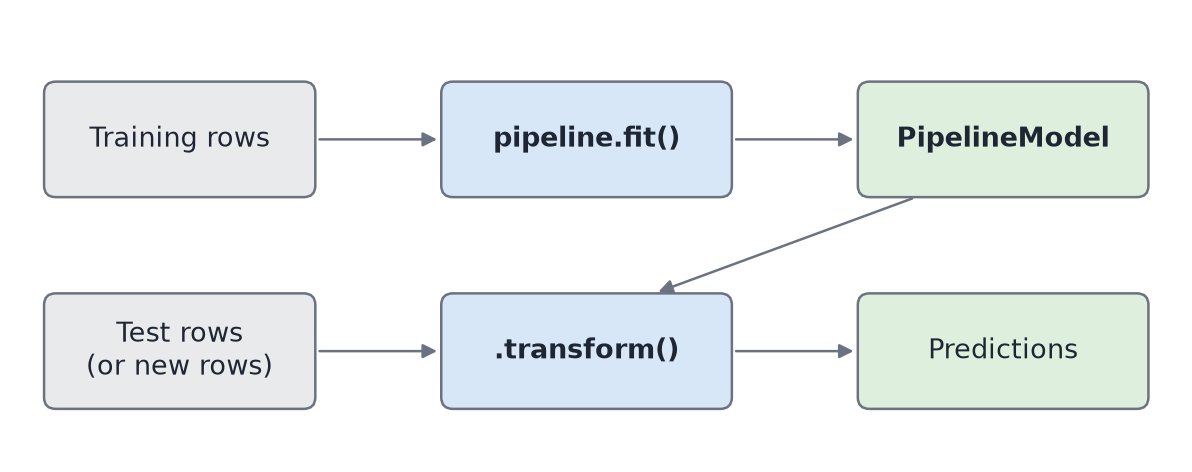

What should you notice?
- Only the **training rows** go into `.fit()`. Everything the pipeline learns (categories, means, model weights) comes from them
- The test rows, and any future rows, only go through `.transform()`: they are prepared with the settings learned from training, never re-learned

### 1.1 Transformers and estimators

Every stage of a pipeline is one of two kinds:

| Kind | Method | What it does | Examples |
|---|---|---|---|
| **Transformer** | `.transform(df)` | applies a fixed rule; learns nothing from the data | `VectorAssembler`, `RegexTokenizer`, `StopWordsRemover`, any fitted model |
| **Estimator** | `.fit(df)` | looks at the data, learns something, and returns a fitted **model**, which is a transformer | `StringIndexer`, `OneHotEncoder`, `StandardScaler`, `CountVectorizer`, `IDF`, `Word2Vec`, `LogisticRegression` |

Kitchen analogy: a transformer is a knife that always cuts the same way. An estimator is tasting the soup to decide how much salt it needs: what it learns depends on which soup you taste.

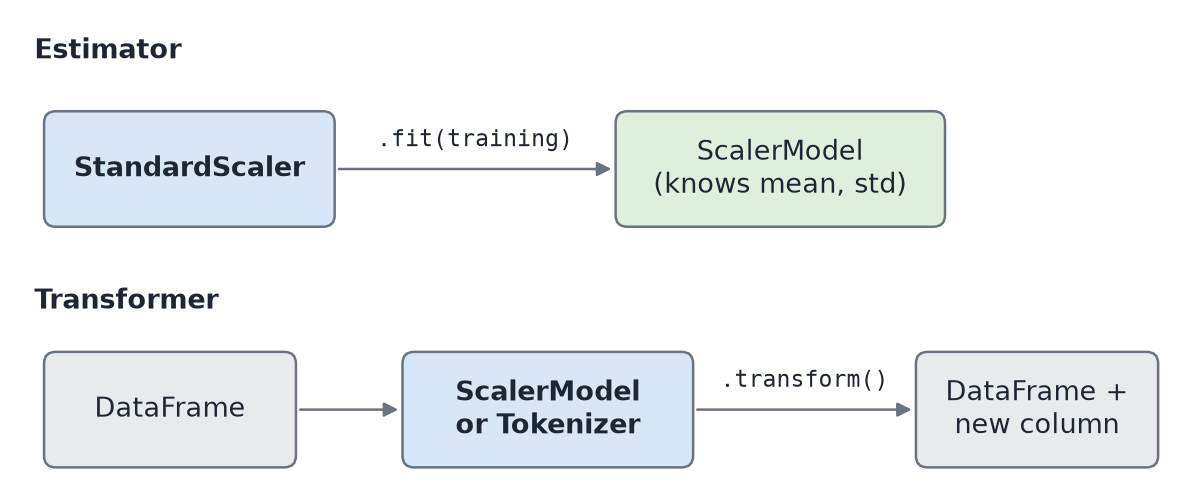

When a pipeline is fitted, it goes through the stages in order: an estimator stage is fitted on the rows as they arrive at that point, and then used to transform them for the next stage; a transformer stage only transforms.

> A `Pipeline` is itself an estimator, and the `PipelineModel` it returns is a transformer. Spark ML has no `fit_transform()` like scikit-learn: the pipeline plays that role.

### 1.2 Data leakage

**Data leakage** happens when information from the test rows reaches the model during training. The test score then looks better than the model really is, like a student who saw the exam questions while studying.

The subtle case is preparation. A `StandardScaler` fitted on all rows learns a mean and a standard deviation that include the test rows:

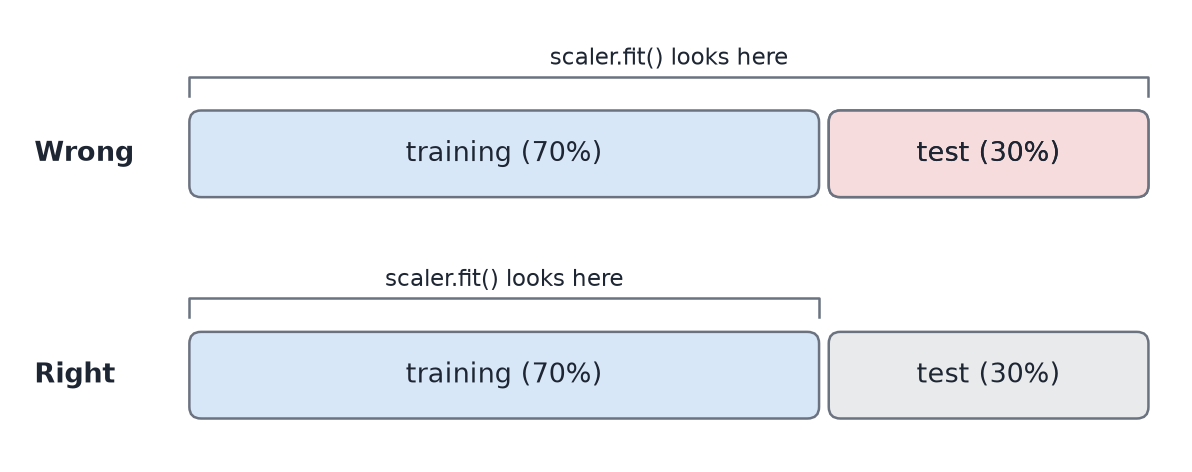

The rule: **split first; fit every estimator on the training rows only; transform both sets.** A pipeline makes this automatic, because `pipeline.fit(training)` is the only place where anything is learned.

> Steps that look at one row at a time, such as computing a property's age from its construction date, learn nothing from other rows. They are safe before the split. Steps that learn from many rows (a list of categories, a mean, a vocabulary of words) belong inside the pipeline.

___

## 2) Setup

The first cell installs the extra Python libraries. It takes about a minute.

In [ ]:
# 2.1 Extra libraries
%pip install matplotlib seaborn mlflow --quiet

In [ ]:
# 2.2 Imports, Spark session and data path
import os

import matplotlib.pyplot as plt
import seaborn as sns
import mlflow

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.functions import col, lit, size, split, concat_ws
from pyspark.sql.types import IntegerType

from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import (StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler,
                                RegexTokenizer, StopWordsRemover, CountVectorizer, IDF, Word2Vec)
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator

spark = SparkSession.builder.appName("HMSPIA_NAPR_pipelines_ISPA").getOrCreate()

# Last week's data file, in the week10 folder next to this one
DATA_PATH = os.path.abspath(os.path.join(os.getcwd(), "..", "week10", "haunted_houses.parquet"))
TARGET = "haunted"
SEED = 42

In [ ]:
# 2.3 A folder for saved models, and an MLflow experiment
# A Unity Catalog volume is a folder in your workspace where Spark can write files
spark.sql("CREATE VOLUME IF NOT EXISTS workspace.default.bda_week11")
VOLUME_PATH = "/Volumes/workspace/default/bda_week11"

# Spark ML on serverless compute needs a folder for temporary files
SPARKML_TEMP_PATH = f"{VOLUME_PATH}/sparkml_temp"
dbutils.fs.mkdirs(SPARKML_TEMP_PATH)
os.environ["SPARKML_TEMP_DFS_PATH"] = SPARKML_TEMP_PATH

# Every model of today is recorded in this experiment, in your home folder
user = spark.sql("SELECT current_user()").first()[0]
EXPERIMENT_NAME = f"/Users/{user}/lab11_ISPA_pipelines"
mlflow.set_experiment(EXPERIMENT_NAME)

In [ ]:
# 2.4 Load the register and repeat last week's row-by-row preparation
properties = spark.read.parquet(DATA_PATH)
properties = properties.na.drop()          # 13 rows with an empty text column

CURRENT_YEAR = 2026
properties = properties \
    .withColumn("property_age", lit(CURRENT_YEAR) - col("construction_date")) \
    .withColumn("sightings_count", size(split(col("sightings"), r"\|")))

bool_cols = ["warning", "teenage_group_disappearance", "foggy", "belltower", "moor_nearby"]
for c in bool_cols + [TARGET]:
    properties = properties.withColumn(c, col(c).cast(IntegerType()))

print("Rows:", properties.count())

Check: `Rows: 4987`.

Every step in 2.4 looks at one row at a time (drop it if it has an empty value, compute its age, turn its true/false into 1/0), so none of them can leak information between rows. Everything that learns from many rows comes next, inside the pipeline.

___

# Part A: a pipeline for "is it haunted?"

## 3) Building the pipeline

### 3.1 Split first

The split comes **before** anything is fitted. We use the same split as last week (70/30, `seed=42`).

In [ ]:
# 3.1 Split 70 / 30
training, test = properties.randomSplit([0.7, 0.3], seed=SEED)
print("Training rows:", training.count())
print("Test rows:    ", test.count())

Check: about 3567 training rows and 1420 test rows.

### 3.2 The stages

These are last week's preparation steps, now written as stages. Nothing is fitted yet: each line only describes a step and which column it reads and writes.

The stages are not a single line. The columns travel along three branches that meet at the end:

- the 2 category columns (`phenomenon_type`, `ghost`) are turned into numbers by `StringIndexer`, then into yes/no columns by `OneHotEncoder`
- the 7 numeric columns are packed into one vector by a first `VectorAssembler`, then scaled by `StandardScaler`
- the 5 yes/no columns are already 0/1, so they go straight to the end
- a second `VectorAssembler` joins the three branches into one `features` column, which `LogisticRegression` reads

Under each box, "learns" marks an estimator and "fixed" a transformer (section 1.1).

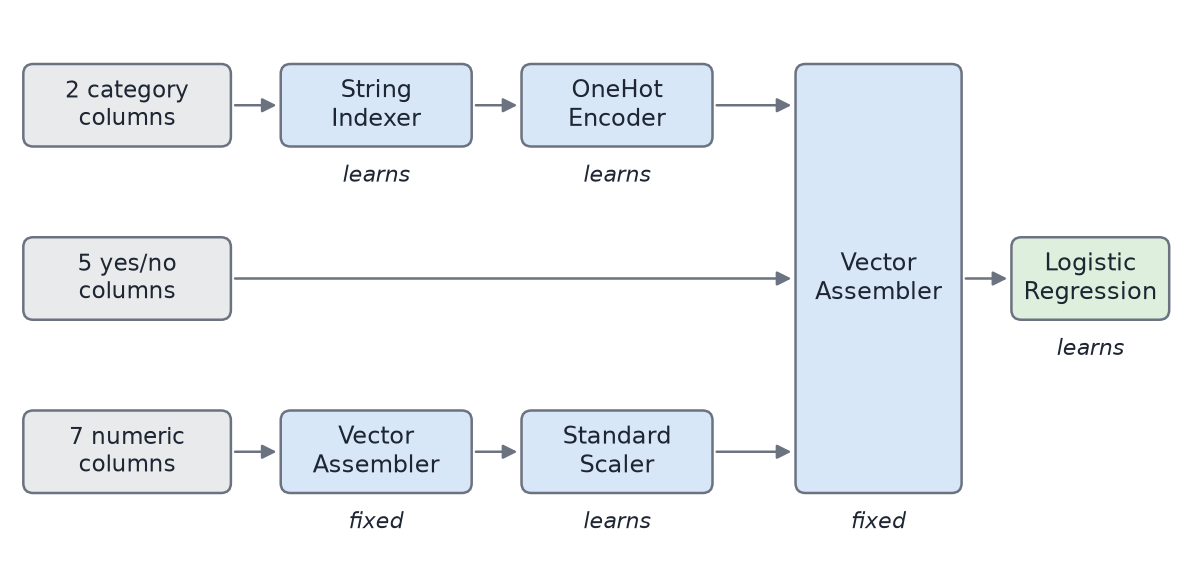

In [ ]:
# 3.2 The stages: the same steps as last week, but nothing is fitted yet
indexer = StringIndexer(
    inputCols=["phenomenon_type", "ghost"],
    outputCols=["phenomenon_idx", "ghost_idx"],
    handleInvalid="keep",              # a category never seen in training gets its own index
)
encoder = OneHotEncoder(
    inputCols=["phenomenon_idx", "ghost_idx"],
    outputCols=["phenomenon_vec", "ghost_vec"],
)

numeric_cols = ["property_age", "sightings_count", "owl_hoots", "villagers_count",
                "disappeared_visitors", "dread", "insurance_exclusion_clauses"]
numeric_assembler = VectorAssembler(inputCols=numeric_cols, outputCol="numeric_features")
scaler = StandardScaler(inputCol="numeric_features", outputCol="numeric_scaled",
                        withMean=True, withStd=True)

feature_assembler = VectorAssembler(
    inputCols=["numeric_scaled"] + bool_cols + ["phenomenon_vec", "ghost_vec"],
    outputCol="features",
)

lr = LogisticRegression(featuresCol="features", labelCol=TARGET)

What should you notice?
- No `.fit()` and no `.transform()`: these are only instructions
- The stages are chained **by column names**: the indexer writes `phenomenon_idx`, the encoder reads `phenomenon_idx`; the numeric assembler writes `numeric_features`, the scaler reads it. A typo in a column name breaks the chain
- The order matters: the encoder cannot run before the indexer has created its input column

## Exercise 1 (Core): build and fit the pipeline

`Pipeline(stages=[...])` takes the stages as a list, in the order they must run. `.fit()` on the pipeline returns a `PipelineModel`, and `.transform()` on that model runs every stage on new rows.

**Goal:** Build a pipeline called `pipeline` with the six stages of 3.2, fit it on `training` (call the result `pipeline_model`), and use it to predict the `test` rows (call the result `test_preds`).

**Concepts:** `Pipeline(stages=[...])`, `.fit()`, `.transform()`, `.select()`, `.show()`

**Expected output:** a table of 5 rows with the columns `haunted`, `probability` and `prediction`.

In [ ]:
# 3.3 Exercise 1
pipeline = Pipeline(stages=[indexer, encoder, numeric_assembler, scaler, feature_assembler, lr])

pipeline_model = pipeline.fit(training)      # every estimator learns from the training rows only
test_preds = pipeline_model.transform(test)  # the test rows are only transformed

test_preds.select(TARGET, "probability", "prediction").show(5, truncate=False)

### 3.4 Looking inside the fitted pipeline

`pipeline_model.stages` lists the fitted stages, in the same order. Each estimator has been replaced by the model it learned.

In [ ]:
# 3.4a The fitted stages
for i, stage in enumerate(pipeline_model.stages):
    print(i, type(stage).__name__)

The scaler model (stage 3) stores the mean it learned. Compare it with the mean of **all** rows, the one a scaler fitted before the split would have learned:

In [ ]:
# 3.4b What the scaler learned (training rows) vs the mean of all rows
scaler_model = pipeline_model.stages[3]
all_rows_means = properties.select([F.mean(c).alias(c) for c in numeric_cols]).first()

for name, learned in zip(numeric_cols, scaler_model.mean.toArray()):
    print(f"{name:28s} training mean {learned:9.2f}   all-rows mean {all_rows_means[name]:9.2f}")

What should you notice?
- The two columns are close but not equal: the scaler learned only from training rows, as it should
- With 5,000 rows and 7 numbers, leaking the test means would change little. With text, the effect is much bigger: a vocabulary learned from all rows would contain words that only appear in test texts (Part B)

Discussion: the fitted pipeline remembers the categories, the means and the model weights. Which of these would be wrong if, next year, HMSPIA started recording a new type of ghost?

### 3.5 Evaluating: weighted and macro F1

Last week we computed F1 from the confusion matrix. Today we use one evaluation function for both parts of the notebook, so it must work with **any number of classes**:
- **Accuracy**: the share of correct predictions
- **F1 of each class**: how well the model finds that class (recall) without false alarms (precision)
- **Weighted F1**: the average of the per-class F1 scores, weighted by how many rows each class has. Built into Spark (`MulticlassClassificationEvaluator`, `metricName="f1"`)
- **Macro F1**: the plain average of the per-class F1 scores; every class counts the same, however rare. Not built into Spark, so the helper computes it from the confusion counts

With imbalanced classes the difference matters. Here: about 85% of the properties are not haunted, so the F1 of the big class dominates the weighted average.

In [ ]:
# 3.5a Evaluation helpers, used in both parts of the notebook
def f1_per_class(preds, label_col):
    """F1 of every class, from the confusion counts.
    The counting is one groupBy in Spark; only the small table of counts comes back."""
    rows = preds.groupBy(label_col, "prediction").count().collect()
    counts = {(float(r[label_col]), float(r["prediction"])): r["count"] for r in rows}
    classes = sorted({truth for truth, _ in counts})

    result = {}
    for c in classes:
        tp = counts.get((c, c), 0)                                             # correct
        fp = sum(n for (t, p), n in counts.items() if p == c and t != c)       # false alarms
        fn = sum(n for (t, p), n in counts.items() if t == c and p != c)       # missed
        result[c] = 2 * tp / (2 * tp + fp + fn) if tp else 0.0
    return result


def evaluate(preds, label_col):
    """Accuracy, weighted F1 (built into Spark) and macro F1 (from f1_per_class)."""
    def spark_metric(name):
        return MulticlassClassificationEvaluator(
            labelCol=label_col, predictionCol="prediction", metricName=name
        ).evaluate(preds)

    per_class = f1_per_class(preds, label_col)
    return {
        "accuracy": spark_metric("accuracy"),
        "f1_weighted": spark_metric("f1"),
        "f1_macro": sum(per_class.values()) / len(per_class),
    }

In [ ]:
# 3.5b Confusion matrix and metrics of the pipeline, on the test set
test_preds.groupBy(TARGET).pivot("prediction", [0.0, 1.0]).count() \
    .na.fill(0).orderBy(TARGET).show()

baseline_scores = evaluate(test_preds, TARGET)
print({k: round(v, 3) for k, v in baseline_scores.items()})
print("F1 per class:", {int(k): round(v, 3) for k, v in f1_per_class(test_preds, TARGET).items()})

What should you notice?
- The F1 of "not haunted" (0) is high and the F1 of "haunted" (1) is much lower: the model misses many haunted properties
- Weighted F1 (0.88) hides this, because 85% of the weight goes to the easy class. Macro F1 (0.74) shows it
- The numbers match last week's logistic regression closely: the pipeline did not change the model, only the way it is built (and now the preparation learned from training rows only)

___

## 4) Saving and loading a pipeline

A fitted pipeline can be saved as a folder of files and loaded later, in another notebook or another job, without retraining. This is how a model goes from an analysis notebook to a tool the client uses every month: the saved pipeline contains **all** the steps, so new rows only need to be in the original raw format.

In [ ]:
# 4.1 Save the fitted pipeline to the volume, then load it back
MODEL_PATH = f"{VOLUME_PATH}/haunted_lr_pipeline"
pipeline_model.write().overwrite().save(MODEL_PATH)

loaded_model = PipelineModel.load(MODEL_PATH)
loaded_scores = evaluate(loaded_model.transform(test), TARGET)
print("Macro F1, original:", round(baseline_scores["f1_macro"], 4))
print("Macro F1, loaded:  ", round(loaded_scores["f1_macro"], 4))

Check: the two numbers are identical.

In [ ]:
# 4.2 Scoring "new" field reports: raw columns in, prediction out, no label needed
new_reports = test.drop(TARGET).limit(5)

loaded_model.transform(new_reports) \
    .select("name", "phenomenon_type", "dread", "probability", "prediction") \
    .show(truncate=False)

What should you notice?
- `new_reports` has no `haunted` column, and it still works: the label is only needed for training and grading
- Nobody had to remember the order of the steps, the categories or the means: they are inside the saved pipeline

> You can see the saved folder in the Catalog panel: `workspace` > `default` > `bda_week11`.

___

## 5) Hyperparameter tuning with CrossValidator

### 5.1 Why not tune on the test set?

A **hyperparameter** is a setting chosen before training (last week: a tree's `maxDepth`). To choose it, we try several values and keep the best. But if "best" means "best on the test set", the test set has helped choose the model, and its score is no longer an honest grade: we picked the setting that happened to suit those particular rows.

So the test set stays aside, and the choosing happens inside the training set. **k-fold cross-validation** splits the training rows into k parts (folds). Each round trains on k-1 folds and scores on the remaining one (the **validation** fold). Every combination of hyperparameters is scored in every round, and its k scores are averaged.

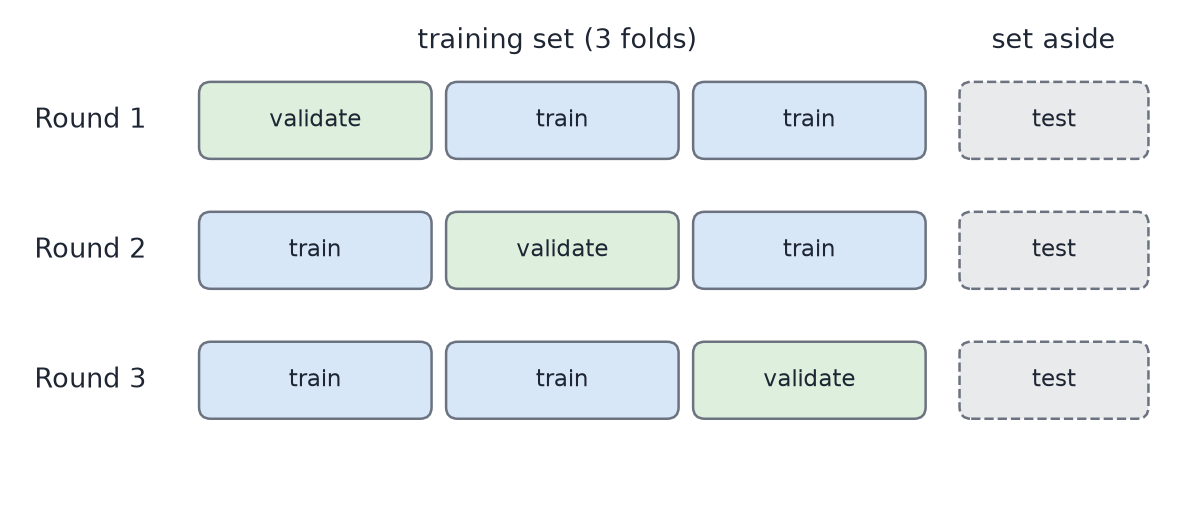

What should you notice?
- Every training row is used for validation exactly once
- The test set is not touched until the very end, once, to grade the winner
- The cost: with 3 folds and 6 combinations, Spark fits the pipeline 3 x 6 = 18 times, plus once more on all training rows with the winning settings

### 5.2 The hyperparameters of logistic regression

Logistic regression can overfit too, by giving very large weights to features that only happen to work on the training rows. **Regularisation** adds a penalty for large weights, which keeps the model simpler:
- `regParam`: how strong the penalty is. `0.0` means no penalty
- `elasticNetParam`: what kind of penalty. `0.0` (called **L2**, or ridge) shrinks all weights a little; `1.0` (called **L1**, or lasso) pushes the weights of unhelpful features to exactly 0, so it also selects features

### 5.3 The leakage trap in cross-validation

The `estimator` we give to `CrossValidator` is the **whole pipeline**, not just `lr`. Then, in every round, the indexer and the scaler are refitted on that round's training folds, and they never see its validation fold. If we prepared the data once and only cross-validated `lr`, the scaler would have seen every validation fold: the leak of 1.2, inside the training set.

`ParamGridBuilder` lists the combinations to try: each `.addGrid(parameter, values)` adds one hyperparameter, and the grid contains every combination.

We also choose what "best" means. Here we tune on the **F1 of the haunted class** (`metricName="fMeasureByLabel"`, `metricLabel=1.0`): finding haunted properties is the point of the model, and the weighted F1 would mostly reward the easy class.

In [ ]:
# 5.3 Cross-validated grid search for the logistic regression pipeline
param_grid = (ParamGridBuilder()
              .addGrid(lr.regParam, [0.0, 0.01, 0.1])
              .addGrid(lr.elasticNetParam, [0.0, 1.0])
              .build())

f1_haunted = MulticlassClassificationEvaluator(
    labelCol=TARGET, predictionCol="prediction",
    metricName="fMeasureByLabel", metricLabel=1.0,
)

cross_validator = CrossValidator(
    estimator=pipeline,                 # the whole pipeline: preparation is refitted in every fold
    estimatorParamMaps=param_grid,
    evaluator=f1_haunted,
    numFolds=3,
    seed=SEED,
)

cv_model = cross_validator.fit(training)     # takes a few minutes: 19 fits

best_lr = cv_model.bestModel.stages[-1]
print("Best regParam:       ", best_lr.getRegParam())
print("Best elasticNetParam:", best_lr.getElasticNetParam())

In [ ]:
# 5.4 Average validation score of every combination
combo_names = [f"reg={p[lr.regParam]}, L1 share={p[lr.elasticNetParam]}" for p in param_grid]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(combo_names, cv_model.avgMetrics, color="#9AB8D8")
ax.set_xlabel("average validation F1 of the haunted class (3 folds)")
ax.set_xlim(0, max(cv_model.avgMetrics) + 0.1)
plt.tight_layout()
plt.show()

cv_scores = evaluate(cv_model.transform(test), TARGET)   # the test set, used once
print("Tuned pipeline on the test set:", {k: round(v, 3) for k, v in cv_scores.items()})

What should you notice?
- The stronger the penalty, the lower the score. With `regParam=0.1` and L1 the bar disappears: the penalty pushes every weight to 0, the model answers "not haunted" for every property, and the F1 of the haunted class is 0. This is underfitting: a model too simple to see the pattern
- No penalty at all (`regParam=0.0`) wins, so the tuned pipeline is the same model as in section 3, with the same test scores. With 5,000 rows and about 70 features this model was not overfitting, and the grid search confirms it. That is a valid result too: tuning does not always improve a model
- With thousands of word features (Part B, and your project) the picture changes, and a penalty helps (see the optional challenge)
- `cv_model` behaves like a fitted pipeline: `.transform(test)` uses the best pipeline, refitted on all the training rows

## Exercise 2 (Practice): grid search for a random forest

`RandomForestClassifier(featuresCol=..., labelCol=..., seed=...)` creates a forest; `numTrees` and `maxDepth` are its hyperparameters (last week, section 10.4). A new pipeline can reuse the preparation stages of 3.2 with a different model as the last stage.

**Goal:** Tune a random forest with a grid of `numTrees` in `[20, 50]` and `maxDepth` in `[3, 7]`, using 3-fold cross-validation, the `f1_haunted` evaluator and `seed=SEED`. Call the fitted cross-validator `rf_cv_model`. Then evaluate it once on `test` with `evaluate()` and print the best `numTrees` and `maxDepth`.

**Concepts:** `RandomForestClassifier`, `Pipeline`, `ParamGridBuilder`, `CrossValidator`, `.bestModel.stages[-1]`, `getOrDefault()`

**Expected output:** the best settings and the test metrics. It takes a few minutes (4 combinations x 3 folds + 1 fits). Compare the macro F1 with the tuned logistic regression.

In [ ]:
# 5.5 Exercise 2
rf = RandomForestClassifier(featuresCol="features", labelCol=TARGET, seed=SEED)

# Same preparation, different model: the leakage-safe pipeline for the forest
rf_pipeline = Pipeline(stages=[indexer, encoder, numeric_assembler, scaler, feature_assembler, rf])

rf_grid = (ParamGridBuilder()
           .addGrid(rf.numTrees, [20, 50])
           .addGrid(rf.maxDepth, [3, 7])
           .build())

rf_cross_validator = CrossValidator(estimator=rf_pipeline, estimatorParamMaps=rf_grid,
                                    evaluator=f1_haunted, numFolds=3, seed=SEED)
rf_cv_model = rf_cross_validator.fit(training)

best_rf = rf_cv_model.bestModel.stages[-1]
print("Best numTrees:", best_rf.getOrDefault("numTrees"), " best maxDepth:", best_rf.getOrDefault("maxDepth"))

rf_scores = evaluate(rf_cv_model.transform(test), TARGET)
print("Tuned forest on the test set:", {k: round(v, 3) for k, v in rf_scores.items()})

In [ ]:
# 5.6 Average validation F1 of the haunted class for each forest
for params, avg in zip(rf_grid, rf_cv_model.avgMetrics):
    print(f"numTrees={params[rf.numTrees]:3d}  maxDepth={params[rf.maxDepth]}  ->  {avg:.3f}")

Discussion:
- Some forests score exactly 0. What do they predict for every property? Would the weighted F1 have noticed?
- The forest does not need scaled numbers (a tree only asks "is dread above 45?"), yet we kept the scaler in its pipeline. Does it hurt? Why can it still be convenient to keep one preparation for every model?

Possible answer: the forests with `maxDepth=3` never predict "haunted": with 85% of the rows on one side, shallow trees always end in a majority of non-haunted properties, so the vote is always "not haunted" and the F1 of the haunted class is 0. Their weighted F1 would still be close to 0.8, which is why we tuned on the F1 of the haunted class. The best forest (50 trees, depth 7) reaches a test macro F1 of about 0.63, below the logistic regression (0.74). Scaling does not change which questions a tree can ask (the order of the values stays the same), so it neither helps nor hurts; sharing one preparation keeps the comparison fair and the code shorter.

___

## 6) Experiment tracking with MLflow

Last week `evaluate_model()` recorded every model in **MLflow** for us. Here is what such a recording looks like when written by hand:
- `mlflow.start_run(run_name=...)` opens a **run**: one entry in the experiment
- `mlflow.log_param(name, value)` records a setting (how the model was built)
- `mlflow.log_metric(name, value)` records a result (how well it did)
- A run opened inside another with `nested=True` becomes its child: one parent run for the grid search, one child per combination

The helper below records one model; the next cell records everything trained so far.

In [ ]:
# 6.1 Helper: one MLflow run per model
def log_run(run_name, params, scores, nested=False):
    with mlflow.start_run(run_name=run_name, nested=nested):
        for name, value in params.items():
            mlflow.log_param(name, value)
        for name, value in scores.items():
            mlflow.log_metric(f"test_{name}", value)

In [ ]:
# 6.2 Record the Part A models
log_run("A: logistic regression (pipeline)", {"part": "A", "model": "LogisticRegression"},
        baseline_scores)

# The grid search: a parent run with the test result, one child run per combination
with mlflow.start_run(run_name="A: logistic regression (grid search)"):
    mlflow.log_param("part", "A")
    mlflow.log_param("best_regParam", best_lr.getRegParam())
    mlflow.log_param("best_elasticNetParam", best_lr.getElasticNetParam())
    for name, value in cv_scores.items():
        mlflow.log_metric(f"test_{name}", value)
    for params, avg in zip(param_grid, cv_model.avgMetrics):
        with mlflow.start_run(run_name=f"reg={params[lr.regParam]}, L1={params[lr.elasticNetParam]}",
                              nested=True):
            mlflow.log_param("regParam", params[lr.regParam])
            mlflow.log_param("elasticNetParam", params[lr.elasticNetParam])
            mlflow.log_metric("avg_validation_f1_haunted", avg)

if "rf_scores" in globals():          # only if Exercise 2 was done
    log_run("A: random forest (grid search)",
            {"part": "A", "model": "RandomForestClassifier",
             "numTrees": best_rf.getOrDefault("numTrees"), "maxDepth": best_rf.getOrDefault("maxDepth")},
            rf_scores)
print("Runs recorded in", EXPERIMENT_NAME)

Check: open the Experiments panel (flask icon on the right edge of the notebook). You should see the runs, and the grid search run can be expanded to show its 6 children. Section 9 reads them all back as a table.

___

# Part B: a text pipeline for "which phenomenon?"

## 7) Turning text into numbers

### 7.1 The big idea: a bag of words

A model only computes with numbers, so a text must become a list of numbers. The classic recipe:
1. **Tokenisation**: cut the text into words (tokens), in lowercase, without punctuation
2. **Stop words**: remove very common words (`the`, `it`, `with`, ...) that appear in every text and say little about its content
3. **Counting**: give every word of the vocabulary a position in a vector, and count how often each word appears in the text. Word order is lost: the text becomes a **bag of words**
4. **TF-IDF**: re-weight the counts, so that words that appear in many texts weigh less

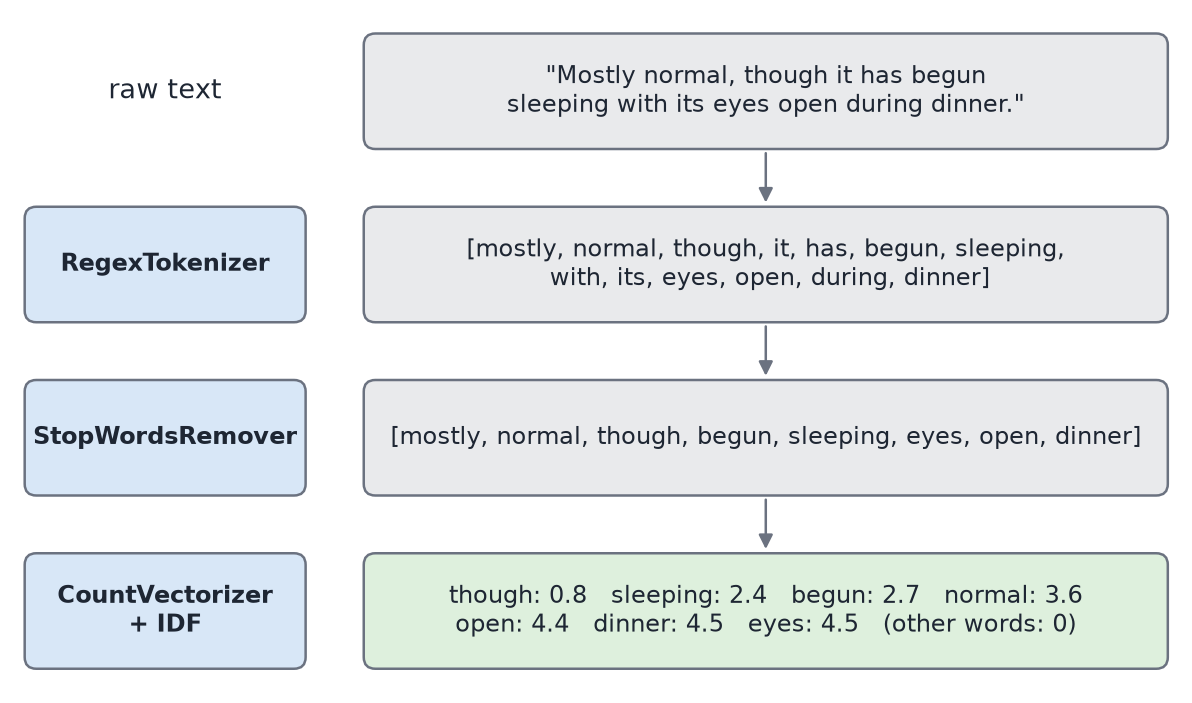

**TF-IDF** stands for term frequency x inverse document frequency:
- **TF**: how many times the word appears in this text
- **IDF**: how rare the word is across all texts. Spark uses `log((number of texts + 1) / (texts containing the word + 1))`. A word in every text gets IDF 0; a word in a few texts gets a large IDF

So a word gets a high TF-IDF when it is frequent in this text **and** rare in the others: exactly the words that describe this text in particular.

> The weights in the picture come from the full pipeline you will build in Exercise 4. `though` is common in the register, so it weighs little; `eyes` and `dinner` are rarer and weigh more. `mostly` gets no position at all: it is not among the 5,000 most frequent words the pipeline keeps.

### 7.2 One text per property

The register has four free-text columns, written by the estate agent, about the cat, by the vicar and by the owner. We join them into one text per property, and from now on the model sees **only this text**, as in the project, where `Text` is the only input.

> `previous_owners_fate` and `archaeology_report_status` look like text but take only 22 and 16 fixed sentences: they are categories, not free text, so we leave them out.

In [ ]:
# 7.2 One text per property, and the class we want to predict
TEXT_COLS = ["estate_agent_euphemism", "cat_behaviour", "vicar_response", "most_recent_excuse"]
LABEL_COL = "phenomenon_type"

texts = properties.select(
    "name",
    LABEL_COL,
    concat_ws(" ", *[col(c) for c in TEXT_COLS]).alias("text"),
)
texts.show(3, truncate=110)

texts.select(F.size(F.split("text", " ")).alias("words_per_text")).describe().show()

What should you notice?
- Each property now has one `text` of about 118 words on average, and its `phenomenon_type`
- The texts are written in a very particular style: long sentences, polite understatement, many rare words

## Exercise 3 (Core): how balanced are the 18 classes?

The same tools as last week's Exercise 1: `groupBy()` and `count()`, a percentage with `withColumn()`, and `orderBy()` with `F.desc()` to sort from the biggest group.

**Goal:** Count the properties of each `phenomenon_type` in `texts`, add a column `pct` with the percentage of all properties (1 decimal), and show all classes from the most to the least frequent.

**Concepts:** `groupBy()`, `count()`, `withColumn()`, `F.round()`, `orderBy()`, `F.desc()`, `.show(n, truncate=False)`

**Expected output:** 18 rows. The biggest class is `haunting` (11.3%), the smallest `unexplained drop in candle sales` (2.8%).

In [ ]:
# 7.3 Exercise 3
total_texts = texts.count()

texts.groupBy(LABEL_COL).count() \
    .withColumn("pct", F.round(F.col("count") / total_texts * 100, 1)) \
    .orderBy(F.desc("count")) \
    .show(18, truncate=False)

Discussion:
- A lazy model that always answers `haunting` would be right 11.3% of the time; random guessing among 18 classes, about 5.6%. Keep both numbers as reference points
- The biggest class has about four times more examples than the smallest. Which classes do you expect the model to find worst, and why?

### 7.4 Step by step on one sentence

Before the full pipeline, here is each step on a short sentence from `cat_behaviour`. Tokenisers and the stop-word remover are transformers, so `.transform()` is enough.

In [ ]:
# 7.4a Tokenise, then remove stop words
example = spark.createDataFrame(
    [("Mostly normal, though it has begun sleeping with its eyes open during dinner.",)], ["text"]
)

tokenizer = RegexTokenizer(inputCol="text", outputCol="tokens",
                           pattern="[^a-z]+",       # split on anything that is not a letter
                           toLowercase=True)
remover = StopWordsRemover(inputCol="tokens", outputCol="words")   # Spark's English stop-word list

steps = remover.transform(tokenizer.transform(example))
for c in ["text", "tokens", "words"]:
    print(f"{c:7s}", steps.first()[c])

What should you notice?
- `RegexTokenizer` lowercases first, then cuts wherever the **pattern** matches. `[^a-z]+` means "one or more characters that are not a letter", so spaces, commas and the final full stop all disappear
- The simpler `Tokenizer` only cuts at spaces, so `normal,` and `dinner.` would keep their punctuation and count as different words from `normal` and `dinner`
- `StopWordsRemover` dropped `it`, `has`, `with`, `its`, `during`, ... The remaining words carry the content

Counting and IDF are estimators: they learn the vocabulary and the document frequencies from the texts they are fitted on. On three short texts from the register:

In [ ]:
# 7.4b CountVectorizer and IDF fitted on three short texts
three_texts = spark.createDataFrame([
    ("Mostly normal, though it has begun sleeping with its eyes open during dinner.",),
    ("Sleeps through the night without incident, though occasionally declines her supper on Thursdays.",),
    ("Indifferent, largely absent, occasionally destructive toward the owner's correspondence.",),
], ["text"])
three_words = remover.transform(tokenizer.transform(three_texts))

count_model = CountVectorizer(inputCol="words", outputCol="counts").fit(three_words)
three_counts = count_model.transform(three_words)
idf_model = IDF(inputCol="counts", outputCol="tfidf").fit(three_counts)

for word, weight in zip(count_model.vocabulary, idf_model.idf.toArray()):
    print(f"{word:16s} IDF = {weight:.2f}")

What should you notice?
- `occasionally` and `though` appear in 2 of the 3 texts, so their IDF (0.29) is lower than that of the words that appear in only one text (0.69): they tell the texts apart less well
- `though` survived the stop-word list: no list is perfect, and you can pass your own with `StopWordsRemover(stopWords=[...])`
- `CountVectorizer` lists the most frequent words first; each word's position in this list is its position in the vector

> **CountVectorizer or HashingTF?** `CountVectorizer` builds a real vocabulary, so you can read back which word is at each position (we use this in 7.7). `HashingTF` (last week's challenge) skips the vocabulary: a fixed formula sends each word to a position. It needs one pass less over the data and no vocabulary in memory, which matters with billions of texts, but two words can land on the same position and you cannot read the words back.

## Exercise 4 (Core): the text classification pipeline

This is the central exercise of today, and the one closest to your project. The pipeline has six stages:

| Stage | Settings | Reads | Writes |
|---|---|---|---|
| `StringIndexer` | | `phenomenon_type` | `label` (0 to 17) |
| `RegexTokenizer` | `pattern="[^a-z]+"`, `toLowercase=True` | `text` | `tokens` |
| `StopWordsRemover` | | `tokens` | `words` |
| `CountVectorizer` | `vocabSize=5000` (keep the 5,000 most frequent words), `minDF=3` (ignore words in fewer than 3 texts) | `words` | `counts` |
| `IDF` | | `counts` | `features` |
| `LogisticRegression` | `featuresCol="features"`, `labelCol="label"`, `maxIter=50` | `features`, `label` | `prediction`, ... |

With more than two classes, `LogisticRegression` switches to its **multinomial** form by itself: one set of weights per class, and a probability for each of the 18 classes.

**Goal:** Split `texts` 70/30 with `seed=SEED` into `train_text` and `test_text`. Define the six stages with exactly these variable names: `label_indexer`, `tokenizer`, `remover`, `count_vectorizer`, `idf`, `text_lr` (sections 8 and 9 reuse them). Build `text_pipeline`, fit it on `train_text` (`text_model`), and predict `test_text` (`text_preds`).

**Concepts:** `randomSplit()`, `StringIndexer`, `RegexTokenizer`, `StopWordsRemover`, `CountVectorizer`, `IDF`, `LogisticRegression`, `Pipeline`, `.fit()`, `.transform()`

**Expected output:** the training and test row counts, then 5 rows of `phenomenon_type`, `label` and `prediction`. Fitting takes about a minute.

In [ ]:
# 7.5 Exercise 4
train_text, test_text = texts.randomSplit([0.7, 0.3], seed=SEED)
print("Training texts:", train_text.count(), " test texts:", test_text.count())

label_indexer = StringIndexer(inputCol=LABEL_COL, outputCol="label")
tokenizer = RegexTokenizer(inputCol="text", outputCol="tokens", pattern="[^a-z]+", toLowercase=True)
remover = StopWordsRemover(inputCol="tokens", outputCol="words")
count_vectorizer = CountVectorizer(inputCol="words", outputCol="counts", vocabSize=5000, minDF=3)
idf = IDF(inputCol="counts", outputCol="features")
text_lr = LogisticRegression(featuresCol="features", labelCol="label", maxIter=50)

text_pipeline = Pipeline(stages=[label_indexer, tokenizer, remover, count_vectorizer, idf, text_lr])
text_model = text_pipeline.fit(train_text)
text_preds = text_model.transform(test_text)

text_preds.select(LABEL_COL, "label", "prediction").show(5, truncate=False)

### 7.6 How good is it, class by class?

`label` is a number; the fitted indexer (stage 0 of `text_model`) keeps the class names in the same order, so we can put the names back.

In [ ]:
# 7.6 Metrics on the test texts, and the F1 of every class
text_scores = evaluate(text_preds, "label")
train_text_scores = evaluate(text_model.transform(train_text), "label")
print("Test: ", {k: round(v, 3) for k, v in text_scores.items()})
print("Train:", {k: round(v, 3) for k, v in train_text_scores.items()})

class_names = text_model.stages[0].labels          # index -> class name
per_class = f1_per_class(text_preds, "label")
pairs = sorted((f1, class_names[int(c)]) for c, f1 in per_class.items())

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh([name for _, name in pairs], [f1 for f1, _ in pairs], color="#9AB8D8")
ax.axvline(text_scores["f1_macro"], color="#3E8E5A", ls="--", label="macro F1")
ax.set_xlabel("F1 on the test texts")
ax.set_xlim(0, 1)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

What should you notice?
- From the text alone, the model finds the right phenomenon about 67% of the time, against 11.3% for the lazy answer and 5.6% for a random guess
- Some classes are found almost perfectly, others badly; the macro F1 (the dashed line) is the average of these bars, each class counting the same
- This time the macro F1 (0.72) is **higher** than the weighted F1 (0.67). Weighted F1 gives more weight to the big classes, so the big classes must be the ones the model finds worst. Macro F1 is not always the lower one: it simply does not care about class sizes
- Training accuracy (1.00) is far above test accuracy (0.67): with 5,000 word features and about 3,500 training texts, the model learns the training texts by heart. This is overfitting, and section 5.2 gave one remedy: regularisation (see the optional challenge)

Discussion: the classes with the lowest F1, are they the rarest ones (Exercise 3)? If not, what else could make a phenomenon hard to recognise from the text?

Possible answer: no. The rarest classes (candle sales, burning portraits, genealogical revelations) are among the best found, and the worst are big, general classes: `spectral apparition`, `haunting`, `possession`, `poltergeist`. A phenomenon is easy when it comes with its own words that appear nowhere else (portraits, coal cellar, organ). It is hard when its words (ghost, haunted, apparition, presence) appear in the texts of many other phenomena too. The amount of data matters less than how distinctive the vocabulary is.

### 7.7 What did the model learn?

The multinomial logistic regression has one weight per word **for every class**. The words with the largest positive weights for a class are the ones that push a text towards it. `CountVectorizer`'s vocabulary turns positions back into words.

In [ ]:
# 7.7 The five words that push most towards each class
vocabulary = text_model.stages[3].vocabulary
weights = text_model.stages[-1].coefficientMatrix.toArray()    # one row per class, one column per word

for i, name in enumerate(class_names):
    top = weights[i].argsort()[::-1][:5]
    print(f"{name:46s} {', '.join(vocabulary[j] for j in top)}")

What should you notice?
- Many top words simply **name** the phenomenon or something tied to it (an organ for the recitals, portraits for the burning portraits, candles for the candle sales)
- The model is not "understanding" the stories: it spots keywords

Discussion: these texts were written **after** the investigation, by people who knew what had happened. Is the model predicting the phenomenon, or reading the investigators' conclusion back from their own words? In the Mental Health project, think about the opposite risk: a text can contain the word "happy" in a sad sentence ("I used to be happy").

___

## 8) Word2Vec: words as points in space

### 8.1 The big idea

In a bag of words every word is its own column: `ghost` and `spectre` are as unrelated as `ghost` and `jam`. **Word2Vec** learns a short list of numbers (an **embedding**, here 100 numbers) for each word, so that words used in **similar contexts** get similar lists. The linguist J. R. Firth put the idea as "you shall know a word by the company it keeps".

Word2Vec is a small neural network trained on a simple game: from a word, guess the words around it in the sentence. To play well, it must give words that appear among the same neighbours similar numbers.

Below, the 100 numbers of a few words from our texts, squeezed to 2 dimensions so that they fit on a page (a model trained on these texts; your numbers will differ a little):

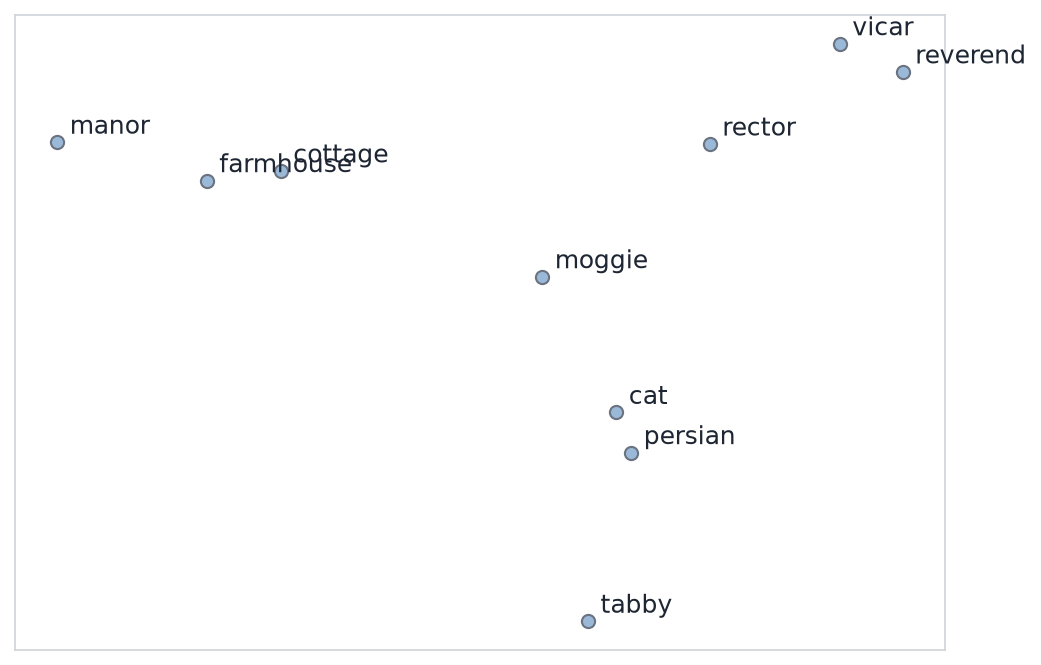

What should you notice?
- Words about the same thing sit together: the cat words, the church words, the house words
- The axes mean nothing by themselves; only the distances matter

To turn a whole text into one vector, Spark's `Word2Vec` takes the **average** of the vectors of its words. Every text then has 100 numbers, whatever its length, instead of 5,000 mostly empty positions.

In [ ]:
# 8.2 Word2Vec on its own: train it on the training texts, then ask for neighbours
train_words = remover.transform(tokenizer.transform(train_text))

word2vec = Word2Vec(inputCol="words", outputCol="features",
                    vectorSize=100,     # numbers per word
                    minCount=3,         # ignore words seen fewer than 3 times
                    seed=SEED)
w2v_model = word2vec.fit(train_words)

for word in ["vicar", "cat", "organ"]:
    print(word, "->", [(r["word"], round(r["similarity"], 2))
                       for r in w2v_model.findSynonyms(word, 5).collect()])

What should you notice?
- `findSynonyms` returns the words whose vectors are closest (similarity close to 1 = very close)
- The neighbours are words used in the same kind of sentence, not always true synonyms. Word2Vec learns how words are used in **these** texts, not their dictionary meaning

## Exercise 5 (Practice): Word2Vec inside the text pipeline

`Word2Vec` is an estimator like `CountVectorizer`, so it can replace the counting and TF-IDF stages in a pipeline. Its output column must be the `featuresCol` of the model.

**Goal:** Build `w2v_pipeline` with the stages `label_indexer`, `tokenizer`, `remover`, a new `Word2Vec` (`inputCol="words"`, `outputCol="features"`, `vectorSize=100`, `minCount=3`, `seed=SEED`) and a new `LogisticRegression` (same settings as `text_lr`). Fit it on `train_text`, predict `test_text` (`w2v_preds`), and evaluate it with `evaluate()` (`w2v_scores`).

**Concepts:** `Word2Vec`, `LogisticRegression`, `Pipeline`, `.fit()`, `.transform()`, `evaluate()`

**Expected output:** the three metrics. Compare the macro F1 with the TF-IDF pipeline of Exercise 4.

In [ ]:
# 8.3 Exercise 5
w2v_stage = Word2Vec(inputCol="words", outputCol="features", vectorSize=100, minCount=3, seed=SEED)
w2v_lr = LogisticRegression(featuresCol="features", labelCol="label", maxIter=50)

w2v_pipeline = Pipeline(stages=[label_indexer, tokenizer, remover, w2v_stage, w2v_lr])
w2v_model_full = w2v_pipeline.fit(train_text)
w2v_preds = w2v_model_full.transform(test_text)

w2v_scores = evaluate(w2v_preds, "label")
print("Word2Vec pipeline:", {k: round(v, 3) for k, v in w2v_scores.items()})
print("TF-IDF pipeline:  ", {k: round(v, 3) for k, v in text_scores.items()})

Discussion: which pipeline wins here? Think about 7.7: if a few keywords name the phenomenon, what happens to them when a text of 120 words becomes the **average** of 120 word vectors? When could Word2Vec be the better choice (think of short texts, synonyms, or a model trained on far more text)?

Possible answer: TF-IDF wins clearly (macro F1 about 0.72 against 0.36). The decisive keywords are diluted in the average of a long text, while TF-IDF keeps each of them in its own column with its own weight. Word2Vec helps more when texts are short (few words to average), when the same idea is written with different words (synonyms share neighbours), and when the embeddings are learned from much more text than our 3,500 training texts.

___

## 9) All models side by side

The Part B models are recorded like the Part A ones, and then MLflow gives every run back as one table.

In [ ]:
# 9.1 Record the Part B models
log_run("B: TF-IDF + logistic regression",
        {"part": "B", "features": "TF-IDF", "vocabSize": 5000, "minDF": 3}, text_scores)
if "w2v_scores" in globals():         # only if Exercise 5 was done
    log_run("B: Word2Vec + logistic regression",
            {"part": "B", "features": "Word2Vec", "vectorSize": 100}, w2v_scores)

In [ ]:
# 9.2 Every recorded run of the experiment, best macro F1 first within each part
exp = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
runs_df = mlflow.search_runs(experiment_ids=[exp.experiment_id],
                             filter_string="metrics.test_f1_macro > 0",
                             order_by=["params.part ASC", "metrics.test_f1_macro DESC"])

cols = ["tags.mlflow.runName", "params.part", "metrics.test_accuracy",
        "metrics.test_f1_weighted", "metrics.test_f1_macro"]
display(runs_df[[c for c in cols if c in runs_df.columns]])

> Re-running cells records the same model again as a new run. MLflow keeps the full history; the start time column tells the runs apart.

Discussion:
- In Part A, which model would you hand to HMSPIA, and which metric did you use to decide?
- Part B used **only** text and reached a macro F1 well above the lazy answer. What would you tell a manager about what such a model can and cannot do?
- Would this still work with 100 million texts? Which stages would get slower: the ones that learn from all rows (vocabulary, IDF, Word2Vec, the model) or the ones that look at one row at a time (tokeniser, stop words)?

___

## 10) From today to your project

In the Mental Health project, each social media text has to be classified into one of six classes. Almost every step of Part B carries over:

| Today (Part B) | Project (`mental_health.csv`) | Things to decide |
|---|---|---|
| `text` (four columns joined) | `Text` | Do the texts need cleaning first (links, repeated letters, very long posts)? |
| `phenomenon_type`, 18 classes | `Emotion`, 6 classes | Count the classes first, as in Exercise 3 |
| split 70/30 before any fitting | the same | Split before the vocabulary is learned |
| `RegexTokenizer`, `StopWordsRemover` | the same stages | Should words like "not" or "no" stay? Spark's default list removes them |
| `CountVectorizer` + `IDF`, or `Word2Vec` | the same stages | `vocabSize`, `minDF`; try both kinds of features |
| `LogisticRegression` (multinomial) | the same, or another classifier | Tune with `CrossValidator`, with the whole pipeline inside |
| macro F1, F1 per class | the same | Which emotions are confused with each other, and why? |
| top words per class (7.7) | top words per emotion | Material for the management presentation |
| save the `PipelineModel`, MLflow | the same | Show how the client would score new texts every day |

Questions to think about before you start:
- Who wrote the texts, and who chose each label? What could make a text look like one emotion while its author felt another?
- Are all six classes written in the same way (length, style, capital letters)? If one class comes from a different source, a model can learn the source instead of the emotion: check this in your exploration
- Your dataset is about ten times larger than today's. Which steps of the pipeline will take longer, and which will not?

___

## 11) Summary

- A **pipeline** is an ordered list of stages; `pipeline.fit(training)` returns a `PipelineModel` that runs every step on new rows with `.transform()`
- **Transformers** apply a fixed rule; **estimators** learn from data with `.fit()` and return a model, which is a transformer
- **Data leakage**: anything learned from test rows makes the test score too optimistic. Split first, and keep every estimator inside the pipeline
- A fitted pipeline can be **saved and loaded**, with all its steps, and scores raw rows without a label
- **Cross-validation** chooses hyperparameters inside the training set; the whole pipeline goes inside the `CrossValidator`, and the test set is used once, at the end
- **Regularisation** (`regParam`, `elasticNetParam`) penalises large weights to fight overfitting
- **MLflow** records the settings and results of every run
- Text becomes numbers through **tokenisation**, **stop-word removal**, **counting** and **TF-IDF**, or through **Word2Vec** embeddings averaged over the text
- With many, imbalanced classes, report **macro F1** and the F1 of each class, not only accuracy

___

## 12) Optional challenge: tune and enrich the text pipeline

> **This section is optional and not part of the class.** It is for students who want to go further on their own, in particular for the Mental Health project. Work through it at your own pace, and use the reading list to understand each step.

### Tuning the text pipeline

In 7.6 the TF-IDF pipeline was much better on the training texts than on the test texts: overfitting. Two settings act on it:
- `count_vectorizer.vocabSize`: fewer words = fewer features = less room to memorise
- `text_lr.regParam`: a penalty on large weights (section 5.2)

`CrossValidator` can tune settings of **any** stage of the pipeline, not only of the model, because the grid simply names the parameter of the stage object.

## Exercise 6 (Challenge (optional)): cross-validate the text pipeline

**Goal:** Tune `text_pipeline` with a grid of `count_vectorizer.vocabSize` in `[1000, 5000]` and `text_lr.regParam` in `[0.0, 0.01, 0.1]`, using 3 folds, `seed=SEED` and a `MulticlassClassificationEvaluator` with `labelCol="label"` and `metricName="f1"` (weighted F1: `CrossValidator` needs a built-in Spark metric, and macro F1 is not one). Evaluate the best pipeline once on `test_text` with `evaluate()` and record it with `log_run()`.

**Concepts:** `ParamGridBuilder` with parameters of two different stages, `CrossValidator`, `.bestModel.stages`, `getVocabSize()`, `getRegParam()`

**Expected output:** the best settings and the test metrics. 6 combinations x 3 folds + 1 = 19 fits of the text pipeline: allow 10 to 15 minutes.

In [ ]:
# 12.1 Exercise 6
text_grid = (ParamGridBuilder()
             .addGrid(count_vectorizer.vocabSize, [1000, 5000])
             .addGrid(text_lr.regParam, [0.0, 0.01, 0.1])
             .build())

text_cv = CrossValidator(
    estimator=text_pipeline,
    estimatorParamMaps=text_grid,
    evaluator=MulticlassClassificationEvaluator(labelCol="label", metricName="f1"),
    numFolds=3,
    seed=SEED,
)
text_cv_model = text_cv.fit(train_text)

best_stages = text_cv_model.bestModel.stages
print("Best vocabSize:", best_stages[3].getVocabSize(), " best regParam:", best_stages[-1].getRegParam())

text_cv_scores = evaluate(text_cv_model.transform(test_text), "label")
print("Tuned TF-IDF pipeline:", {k: round(v, 3) for k, v in text_cv_scores.items()})
log_run("B: TF-IDF + logistic regression (grid search)",
        {"part": "B", "features": "TF-IDF",
         "vocabSize": best_stages[3].getVocabSize(), "regParam": best_stages[-1].getRegParam()},
        text_cv_scores)

Possible answer: the winner keeps only 1,000 words and uses the strongest penalty (`regParam=0.1`), and the test macro F1 rises from about 0.72 to 0.75. Both settings make the model simpler, which is what an overfitting model needed. Compare with Part A, where no penalty won: the right amount of regularisation depends on how many features the model has for the number of rows.

### Going further on your own

- **Word pairs (n-grams).** A bag of words loses word order, so "not happy" and "happy" look alike. `NGram(n=2, inputCol="words", outputCol="bigrams")` turns `["not", "happy", "today"]` into `["not happy", "happy today"]`. Count the bigrams with a second `CountVectorizer`, then join both count vectors with a `VectorAssembler` before the model. Remember that `StopWordsRemover` drops "not" by default: pass your own list with `stopWords=[...]` (start from `StopWordsRemover.loadDefaultStopWords("english")`)
- **Class weights.** Rare classes get fewer examples, so the model pays less attention to them. `LogisticRegression(weightCol=...)` accepts a column with a weight per row: give each row the weight `total rows / (number of classes x rows of its class)` and compare the macro F1
- **Exploring the embedding space.** `w2v_model.getVectors()` returns every word with its vector, as a DataFrame. Rename the vector column to `features` and fit a `KMeans` from `pyspark.ml.clustering` on it: do the clusters of words make sense? `ClusteringEvaluator` (silhouette) helps to choose the number of clusters
- **Other classifiers.** `RandomForestClassifier` and `NaiveBayes` (made for word counts: use the `counts` column, not TF-IDF with negative values) also handle many classes. `GBTClassifier` does not: in Spark it handles only two classes

### Reading list

- Spark documentation, ML pipelines (transformers, estimators, saving): https://spark.apache.org/docs/latest/ml-pipeline.html
- Spark documentation, model selection and tuning (`CrossValidator`, `ParamGridBuilder`): https://spark.apache.org/docs/latest/ml-tuning.html
- Spark documentation, feature extraction (`RegexTokenizer`, `StopWordsRemover`, `CountVectorizer`, `IDF`, `Word2Vec`, `NGram`): https://spark.apache.org/docs/latest/ml-features.html
- Spark documentation, classification (multinomial logistic regression, `NaiveBayes`): https://spark.apache.org/docs/latest/ml-classification-regression.html
- MLflow documentation, tracking: https://mlflow.org/docs/latest/ml/tracking/
- Jurafsky and Martin, *Speech and Language Processing*, chapters on naive Bayes and text classification, and on vector semantics and embeddings (free online): https://web.stanford.edu/~jurafsky/slp3/